<a href="https://colab.research.google.com/github/Vishesh-Goyal7/NARAD-QC/blob/main/NARAD_QC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NARAD-QC
### Network Architecture for Routing, Authentication and Delivery in Quantum Communications

## Phase 0 : 06-07-2026T16:15:32 -- 06-07-2026T16:48:53

Goal : Rebuild point to point CrypTon key generation and AES baseline.

Objective : Prove the original point-to-point system is working as the baseline.

In [ ]:
# @title Dependency Installation for Phase 0

!pip install qiskit qiskit-aer pycryptodome pandas matplotlib --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 44.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 3.2 MB/s eta 0:00:00


In [ ]:
# @title Imports and Global Config

import time
import secrets
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

from Crypto.Cipher import AES
from Crypto.Random import get_random_bytes

RNG = np.random.default_rng()
BACKEND = AerSimulator()

QBER_CUTOFF = 0.11
NONCE_LEN = 12

In [ ]:
# @title AES-GCM Engine

def aes_gcm_encrypt(data: bytes, key: bytes) -> bytes:
    nonce = get_random_bytes(NONCE_LEN)
    cipher = AES.new(key, AES.MODE_GCM, nonce=nonce)
    ciphertext, tag = cipher.encrypt_and_digest(data)
    return nonce + ciphertext + tag


def aes_gcm_decrypt(blob: bytes, key: bytes) -> bytes:
    nonce = blob[:NONCE_LEN]
    rest = blob[NONCE_LEN:]
    ciphertext = rest[:-16]
    tag = rest[-16:]

    cipher = AES.new(key, AES.MODE_GCM, nonce=nonce)
    return cipher.decrypt_and_verify(ciphertext, tag)

In [ ]:
# @title BB84 Step 1 : QRNG

def random_bitstring(n: int) -> list[int]:
    return RNG.integers(0, 2, size=n).tolist()


def random_bases(n: int) -> list[int]:
    return RNG.integers(0, 2, size=n).tolist()

In [ ]:
# @title BB84 Step 2 : Qubit Encoding

def encode_qubits(bits: list[int], bases: list[int]) -> list[QuantumCircuit]:
    circuits = []

    for bit, basis in zip(bits, bases):
        qc = QuantumCircuit(1, 1)

        if bit == 1:
            qc.x(0)

        if basis == 1:
            qc.h(0)

        circuits.append(qc)

    return circuits

In [ ]:
# @title BB84 Step 3 : Measure Qubits With Photon Loss Support

def measure_qubits(
    qubits: list,
    bob_bases: list[int],
    eve_present: bool = False
) -> list:

    measured_bits = []

    for i, prepared_qubit in enumerate(qubits):

        # Photon lost in QuantumLink
        if prepared_qubit is None:
            measured_bits.append(None)
            continue

        circuit = prepared_qubit.copy()

        if eve_present:
            eve_basis = int(RNG.integers(0, 2))

            eve_circuit = circuit.copy()

            if eve_basis == 1:
                eve_circuit.h(0)

            eve_circuit.measure(0, 0)

            transpiled_eve = transpile(eve_circuit, BACKEND)
            eve_result = BACKEND.run(
                transpiled_eve,
                shots=1,
                memory=True
            ).result()

            eve_bit = int(eve_result.get_memory()[0])

            circuit = QuantumCircuit(1, 1)

            if eve_bit == 1:
                circuit.x(0)

            if eve_basis == 1:
                circuit.h(0)

        if bob_bases[i] == 1:
            circuit.h(0)

        circuit.measure(0, 0)

        transpiled_bob = transpile(circuit, BACKEND)
        bob_result = BACKEND.run(
            transpiled_bob,
            shots=1,
            memory=True
        ).result()

        measured_bits.append(int(bob_result.get_memory()[0]))

    return measured_bits

In [ ]:
# @title QBER, Sifting, and Key Reconciliation With Photon Loss

def sift_keys(
    alice_bits: list[int],
    alice_bases: list[int],
    bob_bits: list,
    bob_bases: list[int]
) -> tuple[list[int], list[int]]:

    alice_sifted = []
    bob_sifted = []

    for i in range(len(alice_bits)):
        if bob_bits[i] is None:
            continue

        if alice_bases[i] == bob_bases[i]:
            alice_sifted.append(alice_bits[i])
            bob_sifted.append(bob_bits[i])

    return alice_sifted, bob_sifted

def calculate_qber(alice_key: list[int], bob_key: list[int]) -> float:
    if len(alice_key) == 0:
        return 1.0

    errors = sum(a != b for a, b in zip(alice_key, bob_key))
    return errors / len(alice_key)

In [ ]:
# @title One BB84 Round

def bb84_round(
    n_qubits: int = 256,
    eve_present: bool = False
) -> dict:

    alice_bits = random_bitstring(n_qubits)
    alice_bases = random_bases(n_qubits)
    bob_bases = random_bases(n_qubits)

    qubits = encode_qubits(alice_bits, alice_bases)
    bob_bits = measure_qubits(qubits, bob_bases, eve_present=eve_present)

    alice_sifted, bob_sifted = sift_keys(
        alice_bits,
        alice_bases,
        bob_bits,
        bob_bases
    )

    qber = calculate_qber(alice_sifted, bob_sifted)

    accepted = qber <= QBER_CUTOFF

    return {
        "alice_key": alice_sifted,
        "bob_key": bob_sifted,
        "sifted_length": len(alice_sifted),
        "qber": qber,
        "accepted": accepted,
        "eve_present": eve_present
    }

In [ ]:
# @title Accumulate Session Key

def bits_to_bytes(bits: list[int]) -> bytes:
    usable_len = len(bits) - (len(bits) % 8)
    bits = bits[:usable_len]

    return bytes(
        int("".join(map(str, bits[i:i+8])), 2)
        for i in range(0, usable_len, 8)
    )


def generate_bb84_session_key(
    target_bits: int = 128,
    n_qubits_per_round: int = 256,
    max_rounds: int = 30,
    eve_present: bool = False,
    verbose: bool = True
) -> tuple[bytes, dict]:

    collected_bits = []
    round_logs = []

    start_time = time.perf_counter()

    for round_id in range(1, max_rounds + 1):
        result = bb84_round(
            n_qubits=n_qubits_per_round,
            eve_present=eve_present
        )

        round_logs.append({
            "round": round_id,
            "sifted_length": result["sifted_length"],
            "qber": result["qber"],
            "accepted": result["accepted"]
        })

        if verbose:
            print(
                f"Round {round_id}: "
                f"sifted={result['sifted_length']}, "
                f"QBER={result['qber']:.2%}, "
                f"accepted={result['accepted']}"
            )

        if result["accepted"]:
            collected_bits.extend(result["alice_key"])

        if len(collected_bits) >= target_bits:
            break

    elapsed = time.perf_counter() - start_time

    if len(collected_bits) < target_bits:
        raise RuntimeError(
            "Failed to generate enough accepted BB84 key bits."
        )

    final_bits = collected_bits[:target_bits]
    key = bits_to_bytes(final_bits)

    metadata = {
        "target_bits": target_bits,
        "rounds_used": len(round_logs),
        "accepted_rounds": sum(r["accepted"] for r in round_logs),
        "rejected_rounds": sum(not r["accepted"] for r in round_logs),
        "total_sifted_bits": sum(r["sifted_length"] for r in round_logs),
        "keygen_time_s": elapsed,
        "round_logs": round_logs
    }

    return key, metadata

In [ ]:
# @title Phase 0 End to End System COMMENTED OUT

# message = b"NARAD-QC Phase 0: CrypTon baseline reconstruction."

# session_key, meta = generate_bb84_session_key(
#     target_bits=128,
#     n_qubits_per_round=256,
#     max_rounds=30,
#     eve_present=False,
#     verbose=True
# )

# ciphertext = aes_gcm_encrypt(message, session_key)
# decrypted = aes_gcm_decrypt(ciphertext, session_key)

# print("\nSession Key:", session_key.hex())
# print("Key Metadata:", meta)
# print("Ciphertext:", ciphertext.hex())
# print("Decrypted:", decrypted.decode())
# print("Roundtrip OK:", decrypted == message)

In [ ]:
# @title Eve Presence Validation COMMENTED OUT

# try:
#     eve_key, eve_meta = generate_bb84_session_key(
#         target_bits=128,
#         n_qubits_per_round=256,
#         max_rounds=5,
#         eve_present=True,
#         verbose=True
#     )

#     print("Unexpectedly generated key with Eve present.")
#     print(eve_meta)

# except RuntimeError as e:
#     print("Eve disrupted key generation as expected.")
#     print(str(e))

## Phase 1 : 06-07-2026T17:08:12 -- 07-07-2026T16:37:51

Goal : Add distance-dependent photon loss, QBER, keygen latency, and accepted/rejected rounds.

Objective : Evaluate how distance affects QKD in terms of photon loss, QBER, Key generation latency.

Question : How does increasing physical separation affect secure key establishment in CrypTon?

### Phase 1A

QuantumLink and Node classes

In [ ]:
# @title Node Class Definition

ROLE_USER = "USER"
ROLE_REPEATER = "REPEATER"

class Node:
    def __init__(self, name: str, role: str):
        self.name = name
        self.role = role

    def __str__(self):
        return f"{self.name} ({self.role})"

In [ ]:
# @title Create 2 User Nodes

alice = Node(name="Alice", role=ROLE_USER)
bob = Node(name="Bob", role=ROLE_USER)

print(alice)
print(bob)

Alice (USER)
Bob (USER)


In [ ]:
# @title Quantum Link Class

import random
import math

STANDARD_FIBER_ATTENUATION = 0.2  # dB/km


class QuantumLink:
    """
    NARAD-QC Phase 1.1 / 1.2

    Models a physical quantum channel with distance-dependent photon loss.
    Lost photons are represented as None.
    """

    def __init__(
        self,
        source: Node,
        destination: Node,
        distance_km: float,
        attenuation_db_per_km: float = STANDARD_FIBER_ATTENUATION
    ):
        self.source = source
        self.destination = destination
        self.distance_km = distance_km
        self.attenuation = attenuation_db_per_km
        self.status = "ACTIVE"

        # η(d) = 10^(-(αd)/10)
        self.survival_probability = 10 ** (
            -(self.attenuation * self.distance_km) / 10
        )

        self.loss_probability = 1 - self.survival_probability

        self.statistics = {
            "lifetime_sent": 0,
            "lifetime_received": 0,
            "lifetime_lost": 0
        }

    def transmit(self, qubit):
        """
        Transmit one qubit through the quantum link.
        Returns the qubit if it survives, otherwise None.
        """

        self.statistics["lifetime_sent"] += 1

        if random.random() < self.survival_probability:
            self.statistics["lifetime_received"] += 1
            return qubit

        self.statistics["lifetime_lost"] += 1
        return None

    def transmit_batch(self, qubits: list):
        """
        Transmit a batch of qubits.

        Returns:
        - transmitted_qubits: list containing QuantumCircuit objects or None
        - session-level transmission statistics
        """

        transmitted_qubits = []
        survived = 0

        for qubit in qubits:
            received = self.transmit(qubit)
            transmitted_qubits.append(received)

            if received is not None:
                survived += 1

        sent = len(qubits)
        lost = sent - survived

        return {
            "transmitted_qubits": transmitted_qubits,
            "sent": sent,
            "survived": survived,
            "lost": lost,
            "expected_survival_probability": self.survival_probability,
            "observed_survival_probability": survived / sent if sent else 0,
            "survival_percentage": (survived / sent) * 100 if sent else 0
        }

    def reset_statistics(self):
        self.statistics = {
            "lifetime_sent": 0,
            "lifetime_received": 0,
            "lifetime_lost": 0
        }

    def __str__(self):
        return (
            f"\n{'='*60}\n"
            f"Quantum Link\n"
            f"{'='*60}\n"
            f"Source                          : {self.source.name}\n"
            f"Destination                     : {self.destination.name}\n"
            f"Distance                        : {self.distance_km} km\n"
            f"Attenuation                     : {self.attenuation} dB/km\n"
            f"Status                          : {self.status}\n"
            f"Photon Survival Probability     : {self.survival_probability*100:.2f}%\n"
            f"Photon Loss Probability         : {self.loss_probability*100:.2f}%\n"
            f"{'='*60}"
        )

In [ ]:
# @title Testing one Quantum Link

link = QuantumLink(
    source=alice,
    destination=bob,
    distance_km=50
)

print(link)


Quantum Link
Source                          : Alice
Destination                     : Bob
Distance                        : 50 km
Attenuation                     : 0.2 dB/km
Status                          : ACTIVE
Photon Survival Probability     : 10.00%
Photon Loss Probability         : 90.00%


In [ ]:
# @title Testing Batch Transmission

dummy_qubits = [f"Photon_{i}" for i in range(1000)]

result = link.transmit_batch(dummy_qubits)

print("Transmission Statistics\n")

print(f"Sent        : {result['sent']}")
print(f"Survived    : {result['survived']}")
print(f"Lost        : {result['lost']}")
print(f"Survival %  : {result['survival_percentage']:.2f}%")

Transmission Statistics

Sent        : 1000
Survived    : 113
Lost        : 887
Survival %  : 11.30%


In [ ]:
# @title Distance Comparison

distances = [10, 20, 50, 80, 100, 150, 200]

print(
    f"{'Distance':<12}"
    f"{'Survival %':<15}"
    f"{'Loss %':<15}"
)

print("-" * 42)

for d in distances:
    test_link = QuantumLink(alice, bob, d)

    print(
        f"{d:<12}"
        f"{test_link.survival_probability*100:<15.2f}"
        f"{test_link.loss_probability*100:<15.2f}"
    )

Distance    Survival %     Loss %         
------------------------------------------
10          63.10          36.90          
20          39.81          60.19          
50          10.00          90.00          
80          2.51           97.49          
100         1.00           99.00          
150         0.10           99.90          
200         0.01           99.99          


### Phase 1B

Distance --> Attenuation Model --> Testing Over Multiple Distances

In [ ]:
# @title BB84 / Biased-Basis Generator

def random_bases(n: int, z_probability: float = 0.5) -> list[int]:
    """
    Generate random bases.

    0 = Z / computational basis
    1 = X / diagonal basis

    z_probability = 0.5      -> Standard BB84
    z_probability = 0.8      -> Biased BB84
    z_probability = 15/16    -> T12-style biased basis
    """

    return [
        0 if random.random() < z_probability else 1
        for _ in range(n)
    ]


def basis_match_probability(z_probability: float) -> float:
    """
    P(match) = P(Z)^2 + P(X)^2
    """

    return z_probability**2 + (1 - z_probability)**2

In [ ]:
# @title One Distance-Aware BB84 Round With Estimated Photon Budget

import math

def bb84_round_over_link(
    link: QuantumLink,
    target_bits: int = 128,
    transmission_margin: float = 1.3,
    eve_present: bool = False,
    z_probability: float = 0.5
) -> dict:

    p_basis = basis_match_probability(z_probability)

    estimated_photons_required = math.ceil(
        (target_bits * transmission_margin) /
        (p_basis * link.survival_probability)
    )

    n_qubits = max(1, estimated_photons_required)

    alice_bits = random_bitstring(n_qubits)
    alice_bases = random_bases(n_qubits, z_probability=z_probability)
    bob_bases = random_bases(n_qubits, z_probability=z_probability)

    encoded_qubits = encode_qubits(alice_bits, alice_bases)

    transmission = link.transmit_batch(encoded_qubits)
    received_qubits = transmission["transmitted_qubits"]

    bob_bits = measure_qubits(received_qubits, bob_bases, eve_present=eve_present)

    alice_sifted, bob_sifted = sift_keys(alice_bits, alice_bases, bob_bits, bob_bases)

    qber = calculate_qber(alice_sifted, bob_sifted)
    accepted = qber <= QBER_CUTOFF

    return {
        "alice_key": alice_sifted,
        "bob_key": bob_sifted,
        "sifted_length": len(alice_sifted),
        "qber": qber,
        "accepted": accepted,
        "eve_present": eve_present,
        "z_probability": z_probability,
        "basis_match_probability": p_basis,
        "target_bits_for_round": target_bits,
        "transmission_margin": transmission_margin,
        "estimated_photons_required": estimated_photons_required,
        "photons_sent": transmission["sent"],
        "photons_received": transmission["survived"],
        "photons_lost": transmission["lost"],
        "expected_survival_probability": transmission["expected_survival_probability"],
        "observed_survival_probability": transmission["observed_survival_probability"]
    }

In [ ]:
# @title Generate Session Key Over Quantum Link

def generate_bb84_session_key_over_link(
    link: QuantumLink,
    target_bits: int = 128,
    max_rounds: int = 100,
    transmission_margin: float = 1.3,
    eve_present: bool = False,
    z_probability: float = 0.5,
    verbose: bool = True
) -> tuple[bytes, dict]:

    collected_bits = []
    round_logs = []

    start_time = time.perf_counter()

    for round_id in range(1, max_rounds + 1):

        remaining_bits = target_bits - len(collected_bits)

        result = bb84_round_over_link(
            link=link,
            target_bits=remaining_bits,
            transmission_margin=transmission_margin,
            eve_present=eve_present,
            z_probability=z_probability
        )

        round_log = {
            "round": round_id,
            "distance_km": link.distance_km,
            "photons_sent": result["photons_sent"],
            "photons_received": result["photons_received"],
            "photons_lost": result["photons_lost"],
            "observed_survival_probability": result["observed_survival_probability"],
            "sifted_length": result["sifted_length"],
            "qber": result["qber"],
            "accepted": result["accepted"],
            "z_probability": z_probability,
            "basis_match_probability": result["basis_match_probability"],
            "target_bits_for_round": result["target_bits_for_round"],
            "transmission_margin": result["transmission_margin"],
            "estimated_photons_required": result["estimated_photons_required"],
        }

        round_logs.append(round_log)

        if verbose:
            print(
                f"Round {round_id}: "
                f"distance={link.distance_km} km | "
                f"sent={result['photons_sent']} | "
                f"received={result['photons_received']} | "
                f"sifted={result['sifted_length']} | "
                f"QBER={result['qber']:.2%} | "
                f"accepted={result['accepted']}"
            )

        if result["accepted"]:
            collected_bits.extend(result["alice_key"])

        if len(collected_bits) >= target_bits:
            break

    elapsed = time.perf_counter() - start_time

    if len(collected_bits) < target_bits:
        raise RuntimeError(
            "Failed to generate enough accepted BB84 key bits over the quantum link."
        )

    final_bits = collected_bits[:target_bits]
    key = bits_to_bytes(final_bits)

    total_sent = sum(r["photons_sent"] for r in round_logs)
    total_received = sum(r["photons_received"] for r in round_logs)
    total_lost = sum(r["photons_lost"] for r in round_logs)
    total_sifted = sum(r["sifted_length"] for r in round_logs)

    metadata = {
        "source": link.source.name,
        "destination": link.destination.name,
        "distance_km": link.distance_km,
        "target_bits": target_bits,
        "z_probability": z_probability,
        "basis_match_probability": basis_match_probability(z_probability),
        "rounds_used": len(round_logs),
        "accepted_rounds": sum(r["accepted"] for r in round_logs),
        "rejected_rounds": sum(not r["accepted"] for r in round_logs),
        "total_photons_sent": total_sent,
        "total_photons_received": total_received,
        "total_photons_lost": total_lost,
        "observed_survival_probability": total_received / total_sent if total_sent else 0,
        "total_sifted_bits": total_sifted,
        "effective_key_yield": target_bits / total_sent if total_sent else 0,
        "keygen_time_s": elapsed,
        "round_logs": round_logs
    }

    return key, metadata

In [ ]:
# @title Phase 1.2 End-to-End Distance-Aware Test

# distance_link = QuantumLink(
#     source=alice,
#     destination=bob,
#     distance_km=50
# )

# session_key, meta = generate_bb84_session_key_over_link(
#     link=distance_link,
#     target_bits=128,
#     max_rounds=100,
#     eve_present=False,
#     z_probability=0.5,   # Standard BB84
#     verbose=True,
#     transmission_margin = 1.3,
# )

# message = b"NARAD-QC Phase 1.2: Distance-aware BB84 session key."

# ciphertext = aes_gcm_encrypt(message, session_key)
# decrypted = aes_gcm_decrypt(ciphertext, session_key)

# print("\n" + "="*60)
# print("NARAD-QC Phase 1.2 Session Report")
# print("="*60)
# print(f"Source                     : {meta['source']}")
# print(f"Destination                : {meta['destination']}")
# print(f"Distance                   : {meta['distance_km']} km")
# print(f"Target Key Bits            : {meta['target_bits']}")
# print(f"Z-Basis Probability        : {meta['z_probability']}")
# print(f"Basis Match Probability    : {meta['basis_match_probability']*100:.2f}%")
# print(f"Rounds Used                : {meta['rounds_used']}")
# print(f"Total Photons Sent         : {meta['total_photons_sent']}")
# print(f"Total Photons Received     : {meta['total_photons_received']}")
# print(f"Total Photons Lost         : {meta['total_photons_lost']}")
# print(f"Observed Survival          : {meta['observed_survival_probability']*100:.2f}%")
# print(f"Total Sifted Bits          : {meta['total_sifted_bits']}")
# print(f"Effective Key Yield        : {meta['effective_key_yield']*100:.4f}%")
# print(f"Keygen Time                : {meta['keygen_time_s']:.4f} s")
# print(f"AES Roundtrip OK           : {decrypted == message}")
# print("="*60)

In [ ]:
# @title Standard BB84 vs T12-Style Biased Basis

# test_distance = 50
# target_bits = 128

# protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15/16
# }

# comparison_results = []

# for protocol_name, z_prob in protocols.items():

#     test_link = QuantumLink(alice, bob, test_distance)

#     key, meta = generate_bb84_session_key_over_link(
#         link=test_link,
#         target_bits=target_bits,
#         max_rounds=100,
#         eve_present=False,
#         z_probability=z_prob,
#         verbose=False,
#         transmission_margin = 1.3
#     )

#     comparison_results.append({
#         "Protocol": protocol_name,
#         "Distance (km)": test_distance,
#         "Z Probability": z_prob,
#         "Basis Match Probability (%)": meta["basis_match_probability"] * 100,
#         "Rounds Used": meta["rounds_used"],
#         "Photons Sent": meta["total_photons_sent"],
#         "Photons Received": meta["total_photons_received"],
#         "Sifted Bits": meta["total_sifted_bits"],
#         "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
#         "Keygen Time (s)": meta["keygen_time_s"]
#     })

# df_protocol_comparison = pd.DataFrame(comparison_results)
# display(df_protocol_comparison)

In [ ]:
# @title Phase 1.2 Distance Performance : BB84 vs Biased BB84 vs T12

# distances = [10, 50, 80, 100]
# target_bits = 128
# transmission_margin = 1.3

# protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15/16
# }

# distance_sweep_results = []

# for d in distances:
#     for protocol_name, z_prob in protocols.items():

#         test_link = QuantumLink(
#             source=alice,
#             destination=bob,
#             distance_km=d
#         )

#         try:
#             key, meta = generate_bb84_session_key_over_link(
#                 link=test_link,
#                 target_bits=target_bits,
#                 transmission_margin=transmission_margin,
#                 max_rounds=10,
#                 eve_present=False,
#                 z_probability=z_prob,
#                 verbose=False
#             )

#             distance_sweep_results.append({
#                 "Protocol": protocol_name,
#                 "Distance (km)": d,
#                 "Z Probability": z_prob,
#                 "Basis Match Probability (%)": meta["basis_match_probability"] * 100,
#                 "Expected Photon Survival (%)": test_link.survival_probability * 100,
#                 "Observed Photon Survival (%)": meta["observed_survival_probability"] * 100,
#                 "Rounds Used": meta["rounds_used"],
#                 "Photons Sent": meta["total_photons_sent"],
#                 "Photons Received": meta["total_photons_received"],
#                 "Photons Lost": meta["total_photons_lost"],
#                 "Sifted Bits": meta["total_sifted_bits"],
#                 "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
#                 "Keygen Time (s)": meta["keygen_time_s"],
#                 "Status": "SUCCESS"
#             })

#         except RuntimeError as e:
#             distance_sweep_results.append({
#                 "Protocol": protocol_name,
#                 "Distance (km)": d,
#                 "Z Probability": z_prob,
#                 "Basis Match Probability (%)": basis_match_probability(z_prob) * 100,
#                 "Expected Photon Survival (%)": test_link.survival_probability * 100,
#                 "Observed Photon Survival (%)": None,
#                 "Rounds Used": None,
#                 "Photons Sent": None,
#                 "Photons Received": None,
#                 "Photons Lost": None,
#                 "Sifted Bits": None,
#                 "Effective Key Yield (%)": None,
#                 "Keygen Time (s)": None,
#                 "Status": "FAILED"
#             })

# # df_distance_sweep = pd.DataFrame(distance_sweep_results)

In [ ]:
# @title Separate run for 150km

# d = 150

# target_bits = 128
# transmission_margin = 1.3

# protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15/16
# }

# for protocol_name, z_prob in protocols.items():

#     test_link = QuantumLink(
#         source=alice,
#         destination=bob,
#         distance_km=d
#     )

#     try:
#         key, meta = generate_bb84_session_key_over_link(
#             link=test_link,
#             target_bits=target_bits,
#             transmission_margin=transmission_margin,
#             max_rounds=10,
#             eve_present=False,
#             z_probability=z_prob,
#             verbose=False
#         )

#         distance_sweep_results.append({
#             "Protocol": protocol_name,
#             "Distance (km)": d,
#             "Z Probability": z_prob,
#             "Basis Match Probability (%)": meta["basis_match_probability"] * 100,
#             "Expected Photon Survival (%)": test_link.survival_probability * 100,
#             "Observed Photon Survival (%)": meta["observed_survival_probability"] * 100,
#             "Rounds Used": meta["rounds_used"],
#             "Photons Sent": meta["total_photons_sent"],
#             "Photons Received": meta["total_photons_received"],
#             "Photons Lost": meta["total_photons_lost"],
#             "Sifted Bits": meta["total_sifted_bits"],
#             "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
#             "Keygen Time (s)": meta["keygen_time_s"],
#             "Status": "SUCCESS"
#         })

#     except RuntimeError as e:
#         distance_sweep_results.append({
#             "Protocol": protocol_name,
#             "Distance (km)": d,
#             "Z Probability": z_prob,
#             "Basis Match Probability (%)": basis_match_probability(z_prob) * 100,
#             "Expected Photon Survival (%)": test_link.survival_probability * 100,
#             "Observed Photon Survival (%)": None,
#             "Rounds Used": None,
#             "Photons Sent": None,
#             "Photons Received": None,
#             "Photons Lost": None,
#             "Sifted Bits": None,
#             "Effective Key Yield (%)": None,
#             "Keygen Time (s)": None,
#             "Status": "FAILED"
#         })

# # df_distance_sweep = pd.DataFrame(distance_sweep_results)

# # display(df_distance_sweep)

In [ ]:
# @title Separate run for 200km

# d = 200
# target_bits = 128
# transmission_margin = 1.3

# protocols = {
#     "Standard BB84 (50-50)": 0.5,
#     "Biased BB84 (80-20)": 0.8,
#     "T12-style (15/16 - 1/16)": 15/16
# }

# for protocol_name, z_prob in protocols.items():

#     test_link = QuantumLink(
#         source=alice,
#         destination=bob,
#         distance_km=d
#     )

#     try:
#         key, meta = generate_bb84_session_key_over_link(
#             link=test_link,
#             target_bits=target_bits,
#             transmission_margin=transmission_margin,
#             max_rounds=10,
#             eve_present=False,
#             z_probability=z_prob,
#             verbose=False
#         )

#         distance_sweep_results.append({
#             "Protocol": protocol_name,
#             "Distance (km)": d,
#             "Z Probability": z_prob,
#             "Basis Match Probability (%)": meta["basis_match_probability"] * 100,
#             "Expected Photon Survival (%)": test_link.survival_probability * 100,
#             "Observed Photon Survival (%)": meta["observed_survival_probability"] * 100,
#             "Rounds Used": meta["rounds_used"],
#             "Photons Sent": meta["total_photons_sent"],
#             "Photons Received": meta["total_photons_received"],
#             "Photons Lost": meta["total_photons_lost"],
#             "Sifted Bits": meta["total_sifted_bits"],
#             "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
#             "Keygen Time (s)": meta["keygen_time_s"],
#             "Status": "SUCCESS"
#         })

#     except RuntimeError as e:
#         distance_sweep_results.append({
#             "Protocol": protocol_name,
#             "Distance (km)": d,
#             "Z Probability": z_prob,
#             "Basis Match Probability (%)": basis_match_probability(z_prob) * 100,
#             "Expected Photon Survival (%)": test_link.survival_probability * 100,
#             "Observed Photon Survival (%)": None,
#             "Rounds Used": None,
#             "Photons Sent": None,
#             "Photons Received": None,
#             "Photons Lost": None,
#             "Sifted Bits": None,
#             "Effective Key Yield (%)": None,
#             "Keygen Time (s)": None,
#             "Status": "FAILED"
#         })

# df_distance_sweep = pd.DataFrame(distance_sweep_results)

# display(df_distance_sweep)

In [ ]:
# @title Plot: Distance vs Key Generation Time

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Keygen Time (s)"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Key Generation Time (s)")
# plt.title("Distance vs Key Generation Time")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Key Generation Time", dpi=300, bbox_inches="tight")
# plt.show()

In [ ]:
# @title Plot: Distance vs Effective Key Yield

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Effective Key Yield (%)"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Effective Key Yield (%)")
# plt.title("Distance vs Effective Key Yield")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Effective Key Yield", dpi=300, bbox_inches="tight")
# plt.show()

In [ ]:
# @title Plot: Distance vs Photon Survival

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Observed Photon Survival (%)"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Observed Photon Survival (%)")
# plt.title("Distance vs Observed Photon Survival")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Observed Photon Survival", dpi=300, bbox_inches="tight")
# plt.show()

In [ ]:
# @title Plot: Distance vs Photons Sent

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Photons Sent"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Photons Sent")
# plt.title("Distance vs Photons Required for 128-bit Key")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Photons Required for 128-bit Key", dpi=300, bbox_inches="tight")
# plt.show()

In [ ]:
# @title Plot: Distance vs Sifted Bits

# plt.figure(figsize=(10, 6))

# for protocol_name in protocols.keys():
#     subset = df_distance_sweep[df_distance_sweep["Protocol"] == protocol_name]
#     plt.plot(
#         subset["Distance (km)"],
#         subset["Sifted Bits"],
#         marker="o",
#         label=protocol_name
#     )

# plt.xlabel("Distance (km)")
# plt.ylabel("Sifted Bits")
# plt.title("Distance vs Sifted Bits Generated")
# plt.legend()
# plt.grid(True)
# plt.savefig("Phase 1 Distance vs Sifted Bits Generated", dpi=300, bbox_inches="tight")
# plt.show()

In [ ]:
# @title Saving to CSV

# df_distance_sweep.to_csv("distance_sweep_results.csv", index=False)

## Phase 2 : 07-07-2026T16:50:12 -- 09-07-2026T02:17:32

Goal : Add a single repeater so that Alice <--> Bob chain becomes ===> Alice <--> R1 <--> Bob


Objective : Measure whether splitting distance improves stability and key availability.

Question : Can a single repeater improve the effective QKD range and reliability compared to direct transmission?

### Phase 2A

Single Quantum Repeater Abstraction

In [ ]:
# @title Single Repeater Node

r1 = Node(name="R1", role=ROLE_REPEATER)

print(r1)

R1 (REPEATER)


In [ ]:
# @title Bell Pair Abstraction

class BellPair:
    """
    Represents an entangled Bell pair between two nodes.

    In Phase 2A, this is a network-level abstraction.
    It does not simulate the full photonic hardware circuit.
    """

    def __init__(
        self,
        node_a: Node,
        node_b: Node,
        fidelity: float = 1.0,
        source_link_distance_km: float = None
    ):
        self.node_a = node_a
        self.node_b = node_b
        self.fidelity = fidelity
        self.source_link_distance_km = source_link_distance_km

    def involves(self, node: Node) -> bool:
        return self.node_a == node or self.node_b == node

    def other_node(self, node: Node) -> Node:
        if self.node_a == node:
            return self.node_b
        if self.node_b == node:
            return self.node_a

        raise ValueError("Node is not part of this Bell pair.")

    def __str__(self):
        return (
            f"BellPair({self.node_a.name} ↔ {self.node_b.name}, "
            f"F={self.fidelity:.4f})"
        )

In [ ]:
# @title Bell Pair Generation Attempt

def attempt_bell_pair_generation(
    link: QuantumLink,
    source_fidelity: float = 1.0
):
    """
    Attempt to generate a Bell pair across one elementary quantum link.

    Phase 2A abstraction:
    - Success probability is approximated using link photon survival probability.
    - Successful attempt returns a BellPair object.
    - Failed attempt returns None.
    """

    if random.random() < link.survival_probability:
        return BellPair(
            node_a=link.source,
            node_b=link.destination,
            fidelity=source_fidelity,
            source_link_distance_km=link.distance_km
        )

    return None

In [ ]:
# @title Entanglement Swapping

def entanglement_swap(
    left_pair: BellPair,
    right_pair: BellPair,
    repeater: Node,
    swapping_success_probability: float = 1.0
):
    """
    Perform entanglement swapping at the repeater.

    Example:
        left_pair  = BellPair(Alice ↔ R1)
        right_pair = BellPair(R1 ↔ Bob)

    Output:
        BellPair(Alice ↔ Bob)

    The repeater does not learn the key/message.
    It only helps convert two elementary entangled links
    into one end-to-end entangled link.
    """

    if left_pair is None or right_pair is None:
        return None

    if not left_pair.involves(repeater):
        raise ValueError("Left Bell pair does not involve the repeater.")

    if not right_pair.involves(repeater):
        raise ValueError("Right Bell pair does not involve the repeater.")

    if random.random() > swapping_success_probability:
        return None

    end_a = left_pair.other_node(repeater)
    end_b = right_pair.other_node(repeater)

    combined_fidelity = left_pair.fidelity * right_pair.fidelity

    return BellPair(
        node_a=end_a,
        node_b=end_b,
        fidelity=combined_fidelity,
        source_link_distance_km=(left_pair.source_link_distance_km or 0) + (right_pair.source_link_distance_km or 0)
    )

In [ ]:
# @title Single Repeater Swapping Attempt Without Memory

def attempt_single_repeater_connection(
    link_left: QuantumLink,
    link_right: QuantumLink,
    repeater: Node,
    swapping_success_probability: float = 1.0
) -> dict:

    left_pair = attempt_bell_pair_generation(link_left)
    right_pair = attempt_bell_pair_generation(link_right)

    end_to_end_pair = None

    if left_pair is not None and right_pair is not None:
        end_to_end_pair = entanglement_swap(
            left_pair=left_pair,
            right_pair=right_pair,
            repeater=repeater,
            swapping_success_probability=swapping_success_probability
        )

    return {
        "left_pair": left_pair,
        "right_pair": right_pair,
        "end_to_end_pair": end_to_end_pair,
        "left_success": left_pair is not None,
        "right_success": right_pair is not None,
        "swap_success": end_to_end_pair is not None,
        "end_to_end_success": end_to_end_pair is not None,
        "left_survival_probability": link_left.survival_probability,
        "right_survival_probability": link_right.survival_probability,
        "swapping_success_probability": swapping_success_probability
    }

In [ ]:
# @title Direct vs Single Repeater Theoretical Comparison

def compare_direct_vs_single_repeater_theory(
    source: Node,
    repeater: Node,
    destination: Node,
    total_distance_km: float,
    swapping_success_probability: float = 1.0
) -> dict:

    direct_link = QuantumLink(source, destination, total_distance_km)

    segment_distance = total_distance_km / 2

    left_link = QuantumLink(source, repeater, segment_distance)
    right_link = QuantumLink(repeater, destination, segment_distance)

    direct_success_probability = direct_link.survival_probability

    no_memory_repeater_success_probability = left_link.survival_probability * right_link.survival_probability * swapping_success_probability

    direct_expected_attempts = 1 / direct_success_probability if direct_success_probability > 0 else float("inf")

    no_memory_repeater_expected_attempts = 1 / no_memory_repeater_success_probability if no_memory_repeater_success_probability > 0 else float("inf")

    return {
        "total_distance_km": total_distance_km,
        "direct_distance_km": total_distance_km,
        "segment_distance_km": segment_distance,
        "direct_success_probability": direct_success_probability,
        "left_segment_success_probability": left_link.survival_probability,
        "right_segment_success_probability": right_link.survival_probability,
        "swapping_success_probability": swapping_success_probability,
        "no_memory_repeater_success_probability": no_memory_repeater_success_probability,
        "direct_expected_attempts": direct_expected_attempts,
        "no_memory_repeater_expected_attempts": no_memory_repeater_expected_attempts
    }

In [ ]:
# @title Memory-Assisted Single Repeater Model With Bell Pairs

def generate_entanglement_via_single_repeater_with_memory(
    source: Node,
    repeater: Node,
    destination: Node,
    total_distance_km: float,
    swapping_success_probability: float = 1.0,
    memory_lifetime_attempts: int = 10000,
    max_attempts: int = 1000000,
    verbose: bool = False
) -> dict:
    """
    Memory-assisted single quantum repeater model.

    Topology:
        source ---- repeater ---- destination

    Process:
    1. Try generating BellPair(source ↔ repeater).
    2. Try generating BellPair(repeater ↔ destination).
    3. Store successful Bell pairs in quantum memory.
    4. Retry only failed side.
    5. Once both Bell pairs exist, perform entanglement swapping.
    6. Output BellPair(source ↔ destination).
    """

    segment_distance = total_distance_km / 2

    link_left = QuantumLink(source, repeater, segment_distance)
    link_right = QuantumLink(repeater, destination, segment_distance)
    direct_link = QuantumLink(source, destination, total_distance_km)

    left_pair = None
    right_pair = None

    left_memory_age = 0
    right_memory_age = 0

    left_attempts = 0
    right_attempts = 0

    swap_attempts = 0

    left_memory_expirations = 0
    right_memory_expirations = 0

    start_time = time.perf_counter()

    for global_attempt in range(1, max_attempts + 1):

        if left_pair is not None:
            left_memory_age += 1

            if left_memory_age > memory_lifetime_attempts:
                left_pair = None
                left_memory_age = 0
                left_memory_expirations += 1

        if right_pair is not None:
            right_memory_age += 1

            if right_memory_age > memory_lifetime_attempts:
                right_pair = None
                right_memory_age = 0
                right_memory_expirations += 1

        if left_pair is None:
            left_attempts += 1
            generated_left = attempt_bell_pair_generation(link_left)

            if generated_left is not None:
                left_pair = generated_left
                left_memory_age = 0

        if right_pair is None:
            right_attempts += 1
            generated_right = attempt_bell_pair_generation(link_right)

            if generated_right is not None:
                right_pair = generated_right
                right_memory_age = 0

        if left_pair is not None and right_pair is not None:
            swap_attempts += 1
            end_to_end_pair = entanglement_swap(
                left_pair=left_pair,
                right_pair=right_pair,
                repeater=repeater,
                swapping_success_probability=swapping_success_probability
            )

            if end_to_end_pair is not None:
                elapsed = time.perf_counter() - start_time

                return {
                    "source": source.name,
                    "repeater": repeater.name,
                    "destination": destination.name,
                    "total_distance_km": total_distance_km,
                    "segment_distance_km": segment_distance,
                    "direct_survival_probability": direct_link.survival_probability,
                    "segment_survival_probability": link_left.survival_probability,
                    "swapping_success_probability": swapping_success_probability,
                    "memory_lifetime_attempts": memory_lifetime_attempts,
                    "global_attempts_required": global_attempt,
                    "left_attempts": left_attempts,
                    "right_attempts": right_attempts,
                    "swap_attempts": swap_attempts,
                    "left_memory_expirations": left_memory_expirations,
                    "right_memory_expirations": right_memory_expirations,
                    "final_bell_pair": str(end_to_end_pair),
                    "final_fidelity": end_to_end_pair.fidelity,
                    "success": True,
                    "time_s": elapsed
                }

            left_pair = None
            right_pair = None
            left_memory_age = 0
            right_memory_age = 0

        if verbose and global_attempt <= 20:
            print(
                f"Attempt {global_attempt}: "
                f"L_pair={left_pair is not None}, "
                f"R_pair={right_pair is not None}, "
                f"L_age={left_memory_age}, "
                f"R_age={right_memory_age}"
            )

    elapsed = time.perf_counter() - start_time

    return {
        "source": source.name,
        "repeater": repeater.name,
        "destination": destination.name,
        "total_distance_km": total_distance_km,
        "segment_distance_km": segment_distance,
        "direct_survival_probability": direct_link.survival_probability,
        "segment_survival_probability": link_left.survival_probability,
        "swapping_success_probability": swapping_success_probability,
        "memory_lifetime_attempts": memory_lifetime_attempts,
        "global_attempts_required": max_attempts,
        "left_attempts": left_attempts,
        "right_attempts": right_attempts,
        "swap_attempts": swap_attempts,
        "left_memory_expirations": left_memory_expirations,
        "right_memory_expirations": right_memory_expirations,
        "final_bell_pair": None,
        "final_fidelity": None,
        "success": False,
        "time_s": elapsed
    }

In [ ]:
# @title Single Repeater Test

result = generate_entanglement_via_single_repeater_with_memory(
    source=alice,
    repeater=r1,
    destination=bob,
    total_distance_km=100,
    swapping_success_probability=1.0,
    memory_lifetime_attempts=10000,
    max_attempts=1000000,
    verbose=True
)

print("\n")
print("=" * 70)
print("Phase 2A Single Repeater Result")
print("=" * 70)

for k, v in result.items():
    if isinstance(v, float):
        print(f"{k:<35}: {v:.6f}")
    else:
        print(f"{k:<35}: {v}")

print("=" * 70)

Attempt 1: L_pair=False, R_pair=False, L_age=0, R_age=0
Attempt 2: L_pair=False, R_pair=True, L_age=0, R_age=0
Attempt 3: L_pair=False, R_pair=True, L_age=0, R_age=1
Attempt 4: L_pair=False, R_pair=True, L_age=0, R_age=2
Attempt 5: L_pair=False, R_pair=True, L_age=0, R_age=3
Attempt 6: L_pair=False, R_pair=True, L_age=0, R_age=4
Attempt 7: L_pair=False, R_pair=True, L_age=0, R_age=5
Attempt 8: L_pair=False, R_pair=True, L_age=0, R_age=6


Phase 2A Single Repeater Result
source                             : Alice
repeater                           : R1
destination                        : Bob
total_distance_km                  : 100
segment_distance_km                : 50.000000
direct_survival_probability        : 0.010000
segment_survival_probability       : 0.100000
swapping_success_probability       : 1.000000
memory_lifetime_attempts           : 10000
global_attempts_required           : 9
left_attempts                      : 9
right_attempts                     : 2
swap_attempts  

In [ ]:
# @title Distance Sweep Direct vs Single Repeater

phase2_distances = [50, 80, 100, 150, 200, 250, 300]

phase2_results = []

for d in phase2_distances:

    direct_link = QuantumLink(alice, bob, d)
    repeater_result = generate_entanglement_via_single_repeater_with_memory(
        source=alice,
        repeater=r1,
        destination=bob,
        total_distance_km=d,
        swapping_success_probability=1.0,
        memory_lifetime_attempts=10000,
        max_attempts=1000000,
        verbose=False
    )

    phase2_results.append({
        "Distance (km)": d,
        "Direct Survival Probability (%)": direct_link.survival_probability * 100,
        "Direct Expected Attempts": 1 / direct_link.survival_probability,
        "Segment Distance (km)": d / 2,
        "Segment Survival Probability (%)": repeater_result["segment_survival_probability"] * 100,
        "Repeater Global Attempts": repeater_result["global_attempts_required"],
        "Left Link Attempts": repeater_result["left_attempts"],
        "Right Link Attempts": repeater_result["right_attempts"],
        "Swap Attempts": repeater_result["swap_attempts"],
        "Final Bell Pair": repeater_result["final_bell_pair"],
        "Final Fidelity": repeater_result["final_fidelity"],
        "Memory Lifetime": repeater_result["memory_lifetime_attempts"],
        "Left Memory Expirations": repeater_result["left_memory_expirations"],
        "Right Memory Expirations": repeater_result["right_memory_expirations"],
        "Repeater Success": repeater_result["success"],
        "Improvement Factor": (
            (1 / direct_link.survival_probability)
            / repeater_result["global_attempts_required"]
            if repeater_result["global_attempts_required"] > 0
            else None
        )
    })

df_phase2_single_repeater = pd.DataFrame(phase2_results)

display(df_phase2_single_repeater)

df_phase2_single_repeater.to_csv(
    "phase2_single_repeater_results.csv",
    index=False
)

,Distance (km),Direct Survival Probability (%),Direct Expected Attempts,Segment Distance (km),Segment Survival Probability (%),Repeater Global Attempts,Left Link Attempts,Right Link Attempts,Swap Attempts,Final Bell Pair,Final Fidelity,Memory Lifetime,Left Memory Expirations,Right Memory Expirations,Repeater Success,Improvement Factor
0,50,10.000000,10.000000,25.0,31.622777,4,3,4,1,"BellPair(Alice ↔ Bob, F=1.0000)",1.0,10000,0,0,True,2.500000
1,80,2.511886,39.810717,40.0,15.848932,24,24,4,1,"BellPair(Alice ↔ Bob, F=1.0000)",1.0,10000,0,0,True,1.658780
2,100,1.000000,100.000000,50.0,10.000000,12,4,12,1,"BellPair(Alice ↔ Bob, F=1.0000)",1.0,10000,0,0,True,8.333333
3,150,0.100000,1000.000000,75.0,3.162278,124,124,13,1,"BellPair(Alice ↔ Bob, F=1.0000)",1.0,10000,0,0,True,8.064516
4,200,0.010000,10000.000000,100.0,1.000000,191,191,29,1,"BellPair(Alice ↔ Bob, F=1.0000)",1.0,10000,0,0,True,52.356021
5,250,0.001000,100000.000000,125.0,0.316228,194,30,194,1,"BellPair(Alice ↔ Bob, F=1.0000)",1.0,10000,0,0,True,515.463918
6,300,0.000100,1000000.000000,150.0,0.100000,261,261,84,1,"BellPair(Alice ↔ Bob, F=1.0000)",1.0,10000,0,0,True,3831.417625


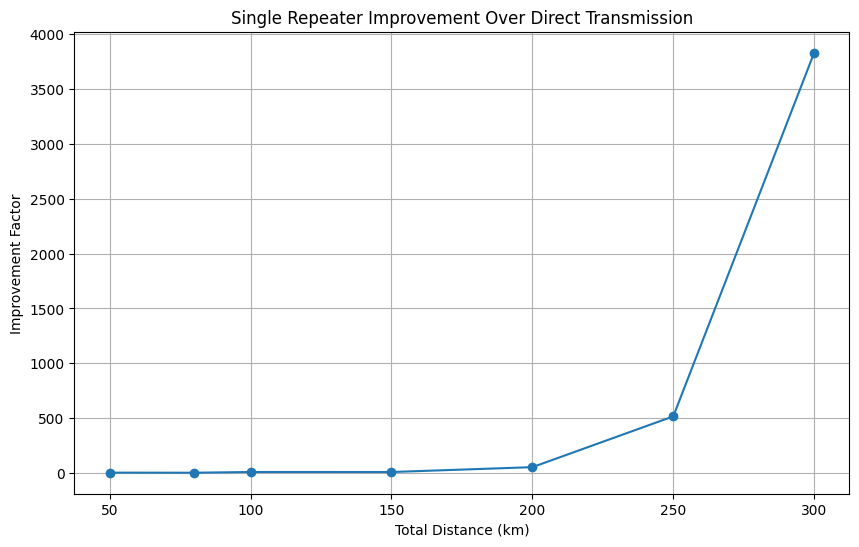

In [ ]:
# @title Repeater Improvement Factor

plt.figure(figsize=(10, 6))

plt.plot(
    df_phase2_single_repeater["Distance (km)"],
    df_phase2_single_repeater["Improvement Factor"],
    marker="o"
)

plt.xlabel("Total Distance (km)")
plt.ylabel("Improvement Factor")
plt.title("Single Repeater Improvement Over Direct Transmission")
plt.grid(True)

plt.savefig(
    "Phase 2 Single Repeater Improvement Over Direct Transmission.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

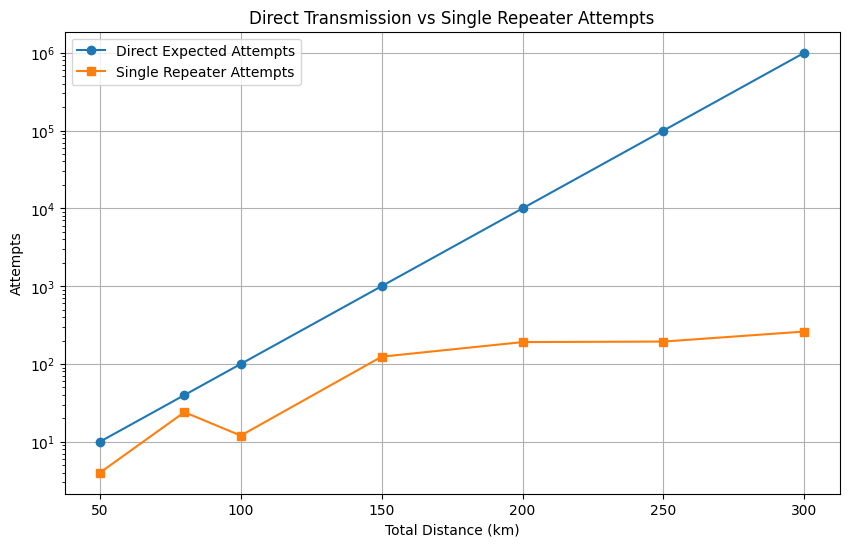

In [ ]:
# @title Direct Expected Attempts vs Repeater Attempts

plt.figure(figsize=(10, 6))

plt.plot(
    df_phase2_single_repeater["Distance (km)"],
    df_phase2_single_repeater["Direct Expected Attempts"],
    marker="o",
    label="Direct Expected Attempts"
)

plt.plot(
    df_phase2_single_repeater["Distance (km)"],
    df_phase2_single_repeater["Repeater Global Attempts"],
    marker="s",
    label="Single Repeater Attempts"
)

plt.xlabel("Total Distance (km)")
plt.ylabel("Attempts")
plt.title("Direct Transmission vs Single Repeater Attempts")
plt.yscale("log")
plt.legend()
plt.grid(True)

plt.savefig(
    "Phase 2 Direct vs Repeater Attempts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Phase 2B

Repeater Assisted QKD Protocols --> AES Key Generation

In [ ]:
# @title Physical Bell Pair Generation

def attempt_bell_pair_generation_physical(
    link: QuantumLink,
    source_fidelity: float = 1.0
):
    """
    Attempts Bell-pair generation over a physical QuantumLink.

    This uses QuantumLink.transmit(), so fiber attenuation and photon loss
    are recorded in the physical layer statistics.
    """

    received = link.transmit("photon")

    if received is not None:
        return BellPair(
            node_a=link.source,
            node_b=link.destination,
            fidelity=source_fidelity,
            source_link_distance_km=link.distance_km
        )

    return None

In [ ]:
# @title Repeater-Assisted Quantum Channel With Layered Statistics

class RepeaterAssistedQuantumChannel:
    """
    Repeater-assisted quantum channel.

    Physical Layer:
    - photons emitted
    - photons survived/lost
    - Bell-pair generation attempts
    - memory expirations
    - entanglement swapping attempts

    Quantum Protocol Layer:
    - qubits requested
    - qubits delivered
    - qubits lost at protocol level
    """

    def __init__(
        self,
        source: Node,
        repeater: Node,
        destination: Node,
        total_distance_km: float,
        swapping_success_probability: float = 1.0,
        memory_lifetime_attempts: int = 10000,
        max_entanglement_attempts: int = 1000000
    ):
        self.source = source
        self.repeater = repeater
        self.destination = destination

        self.total_distance_km = total_distance_km
        self.segment_distance_km = total_distance_km / 2

        self.swapping_success_probability = swapping_success_probability
        self.memory_lifetime_attempts = memory_lifetime_attempts
        self.max_entanglement_attempts = max_entanglement_attempts

        self.left_link = QuantumLink(source, repeater, self.segment_distance_km)
        self.right_link = QuantumLink(repeater, destination, self.segment_distance_km)
        self.direct_link = QuantumLink(source, destination, total_distance_km)

        self.physical_stats = {
            "left_photons_sent": 0,
            "left_photons_survived": 0,
            "left_photons_lost": 0,

            "right_photons_sent": 0,
            "right_photons_survived": 0,
            "right_photons_lost": 0,

            "left_bell_pair_attempts": 0,
            "right_bell_pair_attempts": 0,

            "successful_left_bell_pairs": 0,
            "successful_right_bell_pairs": 0,
            "successful_end_to_end_bell_pairs": 0,

            "swap_attempts": 0,

            "memory_expirations_left": 0,
            "memory_expirations_right": 0,

            "total_entanglement_attempts": 0
        }

        self.protocol_stats = {
            "qubits_requested": 0,
            "qubits_delivered": 0,
            "qubits_lost": 0
        }

    def _sync_physical_stats_from_links(self):
        self.physical_stats["left_photons_sent"] = self.left_link.statistics["lifetime_sent"]
        self.physical_stats["left_photons_survived"] = self.left_link.statistics["lifetime_received"]
        self.physical_stats["left_photons_lost"] = self.left_link.statistics["lifetime_lost"]

        self.physical_stats["right_photons_sent"] = self.right_link.statistics["lifetime_sent"]
        self.physical_stats["right_photons_survived"] = self.right_link.statistics["lifetime_received"]
        self.physical_stats["right_photons_lost"] = self.right_link.statistics["lifetime_lost"]

        self.physical_stats["total_entanglement_attempts"] = (
            self.physical_stats["left_bell_pair_attempts"]
            + self.physical_stats["right_bell_pair_attempts"]
        )

    def generate_end_to_end_bell_pair(self):
        left_pair = None
        right_pair = None

        left_memory_age = 0
        right_memory_age = 0

        for global_attempt in range(1, self.max_entanglement_attempts + 1):

            if left_pair is not None:
                left_memory_age += 1
                if left_memory_age > self.memory_lifetime_attempts:
                    left_pair = None
                    left_memory_age = 0
                    self.physical_stats["memory_expirations_left"] += 1

            if right_pair is not None:
                right_memory_age += 1
                if right_memory_age > self.memory_lifetime_attempts:
                    right_pair = None
                    right_memory_age = 0
                    self.physical_stats["memory_expirations_right"] += 1

            if left_pair is None:
                self.physical_stats["left_bell_pair_attempts"] += 1
                generated_left = attempt_bell_pair_generation_physical(self.left_link)

                if generated_left is not None:
                    left_pair = generated_left
                    left_memory_age = 0
                    self.physical_stats["successful_left_bell_pairs"] += 1

            if right_pair is None:
                self.physical_stats["right_bell_pair_attempts"] += 1
                generated_right = attempt_bell_pair_generation_physical(self.right_link)

                if generated_right is not None:
                    right_pair = generated_right
                    right_memory_age = 0
                    self.physical_stats["successful_right_bell_pairs"] += 1

            if left_pair is not None and right_pair is not None:
                self.physical_stats["swap_attempts"] += 1

                end_to_end_pair = entanglement_swap(
                    left_pair=left_pair,
                    right_pair=right_pair,
                    repeater=self.repeater,
                    swapping_success_probability=self.swapping_success_probability
                )

                if end_to_end_pair is not None:
                    self.physical_stats["successful_end_to_end_bell_pairs"] += 1
                    self._sync_physical_stats_from_links()

                    return {
                        "success": True,
                        "end_to_end_pair": end_to_end_pair,
                        "global_attempts_required": global_attempt
                    }

                left_pair = None
                right_pair = None
                left_memory_age = 0
                right_memory_age = 0

        self._sync_physical_stats_from_links()

        return {
            "success": False,
            "end_to_end_pair": None,
            "global_attempts_required": self.max_entanglement_attempts
        }

    def transmit(self, qubit):
        self.protocol_stats["qubits_requested"] += 1

        result = self.generate_end_to_end_bell_pair()

        if result["success"]:
            self.protocol_stats["qubits_delivered"] += 1
            return qubit

        self.protocol_stats["qubits_lost"] += 1
        return None

    def transmit_batch(self, qubits: list):
        transmitted_qubits = [self.transmit(q) for q in qubits]

        sent = len(qubits)
        delivered = sum(q is not None for q in transmitted_qubits)
        lost = sent - delivered

        self._sync_physical_stats_from_links()

        avg_attempts_per_delivered_qubit = (
            self.physical_stats["total_entanglement_attempts"] / delivered
            if delivered else None
        )

        return {
            "transmitted_qubits": transmitted_qubits,
            "sent": sent,
            "survived": delivered,
            "lost": lost,
            "observed_survival_probability": delivered / sent if sent else 0,
            "physical_stats": self.physical_stats.copy(),
            "protocol_stats": self.protocol_stats.copy(),
            "average_entanglement_attempts_per_delivered_qubit": avg_attempts_per_delivered_qubit
        }

In [ ]:
# @title BB84 Round Over Repeater-Assisted Channel

def bb84_round_over_repeater_channel(
    channel: RepeaterAssistedQuantumChannel,
    target_bits: int = 128,
    transmission_margin: float = 1.3,
    eve_present: bool = False,
    z_probability: float = 0.5
) -> dict:

    p_basis = basis_match_probability(z_probability)

    # Important:
    # In repeater-assisted mode, fiber attenuation is paid inside Bell-pair generation.
    # Therefore protocol qubit budget depends only on basis matching.
    estimated_qubits_required = math.ceil(
        (target_bits * transmission_margin) / p_basis
    )

    alice_bits = random_bitstring(estimated_qubits_required)
    alice_bases = random_bases(estimated_qubits_required, z_probability=z_probability)
    bob_bases = random_bases(estimated_qubits_required, z_probability=z_probability)

    encoded_qubits = encode_qubits(alice_bits, alice_bases)

    transmission = channel.transmit_batch(encoded_qubits)
    received_qubits = transmission["transmitted_qubits"]

    bob_bits = measure_qubits(
        received_qubits,
        bob_bases,
        eve_present=eve_present
    )

    alice_sifted, bob_sifted = sift_keys(
        alice_bits,
        alice_bases,
        bob_bits,
        bob_bases
    )

    qber = calculate_qber(alice_sifted, bob_sifted)
    accepted = qber <= QBER_CUTOFF

    return {
        "alice_key": alice_sifted,
        "bob_key": bob_sifted,
        "sifted_length": len(alice_sifted),
        "qber": qber,
        "accepted": accepted,

        "z_probability": z_probability,
        "basis_match_probability": p_basis,
        "estimated_qubits_required": estimated_qubits_required,

        "qubits_sent": transmission["sent"],
        "qubits_received": transmission["survived"],
        "qubits_lost": transmission["lost"],

        "physical_stats": transmission["physical_stats"],
        "protocol_stats": transmission["protocol_stats"],
        "average_entanglement_attempts_per_delivered_qubit":
            transmission["average_entanglement_attempts_per_delivered_qubit"]
    }

In [ ]:
# @title Generate Session Key Over Repeater-Assisted Channel

def generate_bb84_session_key_over_repeater_channel(
    channel: RepeaterAssistedQuantumChannel,
    target_bits: int = 128,
    transmission_margin: float = 1.3,
    max_rounds: int = 100,
    eve_present: bool = False,
    z_probability: float = 0.5,
    verbose: bool = True
):

    collected_bits = []
    round_logs = []

    start_time = time.perf_counter()

    for round_id in range(1, max_rounds + 1):

        remaining_bits = target_bits - len(collected_bits)

        result = bb84_round_over_repeater_channel(
            channel=channel,
            target_bits=remaining_bits,
            transmission_margin=transmission_margin,
            eve_present=eve_present,
            z_probability=z_probability
        )

        round_logs.append({
            "round": round_id,
            "sifted_length": result["sifted_length"],
            "qber": result["qber"],
            "accepted": result["accepted"],
            "qubits_sent": result["qubits_sent"],
            "qubits_received": result["qubits_received"],
            "qubits_lost": result["qubits_lost"],
            "average_entanglement_attempts_per_delivered_qubit":
                result["average_entanglement_attempts_per_delivered_qubit"]
        })

        if verbose:
            ps = result["physical_stats"]
            avg_attempts = result["average_entanglement_attempts_per_delivered_qubit"]

            print(
                f"Round {round_id}: "
                f"sent={result['qubits_sent']} | "
                f"received={result['qubits_received']} | "
                f"sifted={result['sifted_length']} | "
                f"QBER={result['qber']:.2%} | "
                f"accepted={result['accepted']} | "
                f"entanglement_attempts={ps['total_entanglement_attempts']} | "
                f"avg_attempts/qubit={avg_attempts:.2f}"
            )

        if result["accepted"]:
            collected_bits.extend(result["alice_key"])

        if len(collected_bits) >= target_bits:
            break

    elapsed = time.perf_counter() - start_time

    if len(collected_bits) < target_bits:
        raise RuntimeError(
            "Failed to generate enough key bits over repeater-assisted channel."
        )

    final_bits = collected_bits[:target_bits]
    key = bits_to_bytes(final_bits)

    total_qubits_sent = sum(r["qubits_sent"] for r in round_logs)
    total_qubits_received = sum(r["qubits_received"] for r in round_logs)
    total_qubits_lost = sum(r["qubits_lost"] for r in round_logs)

    ps = channel.physical_stats
    qs = channel.protocol_stats

    total_photons_sent_physical = ps["left_photons_sent"] + ps["right_photons_sent"]
    total_photons_survived_physical = ps["left_photons_survived"] + ps["right_photons_survived"]
    total_photons_lost_physical = ps["left_photons_lost"] + ps["right_photons_lost"]

    metadata = {
        "source": channel.source.name,
        "repeater": channel.repeater.name,
        "destination": channel.destination.name,

        "total_distance_km": channel.total_distance_km,
        "segment_distance_km": channel.segment_distance_km,

        "target_bits": target_bits,
        "z_probability": z_probability,
        "basis_match_probability": basis_match_probability(z_probability),

        "rounds_used": len(round_logs),

        # Protocol layer
        "total_qubits_sent": total_qubits_sent,
        "total_qubits_received": total_qubits_received,
        "total_qubits_lost": total_qubits_lost,
        "effective_key_yield": target_bits / total_qubits_sent if total_qubits_sent else 0,
        "keygen_time_s": elapsed,

        # Physical layer
        "left_photons_sent": ps["left_photons_sent"],
        "left_photons_survived": ps["left_photons_survived"],
        "left_photons_lost": ps["left_photons_lost"],

        "right_photons_sent": ps["right_photons_sent"],
        "right_photons_survived": ps["right_photons_survived"],
        "right_photons_lost": ps["right_photons_lost"],

        "total_photons_sent_physical": total_photons_sent_physical,
        "total_photons_survived_physical": total_photons_survived_physical,
        "total_photons_lost_physical": total_photons_lost_physical,

        "total_entanglement_attempts": ps["total_entanglement_attempts"],
        "average_entanglement_attempts_per_delivered_qubit":
            ps["total_entanglement_attempts"] / total_qubits_received
            if total_qubits_received else None,

        "successful_end_to_end_bell_pairs": ps["successful_end_to_end_bell_pairs"],
        "swap_attempts": ps["swap_attempts"],
        "memory_expirations_left": ps["memory_expirations_left"],
        "memory_expirations_right": ps["memory_expirations_right"],

        "protocol_qubits_requested": qs["qubits_requested"],
        "protocol_qubits_delivered": qs["qubits_delivered"],
        "protocol_qubits_lost": qs["qubits_lost"],

        "round_logs": round_logs
    }

    return key, metadata

In [ ]:
# @title Fixed Distance Protocol Comparison

test_distance = 100
target_bits = 128
transmission_margin = 1.3

protocols = {
    "Standard BB84 (50-50)": 0.5,
    "Biased BB84 (80-20)": 0.8,
    "T12-style (15/16 - 1/16)": 15/16
}

phase2b_fixed_results = []

for protocol_name, z_prob in protocols.items():

    channel = RepeaterAssistedQuantumChannel(
        source=alice,
        repeater=r1,
        destination=bob,
        total_distance_km=test_distance,
        swapping_success_probability=1.0,
        memory_lifetime_attempts=10000,
        max_entanglement_attempts=1000000
    )

    key, meta = generate_bb84_session_key_over_repeater_channel(
        channel=channel,
        target_bits=target_bits,
        transmission_margin=transmission_margin,
        max_rounds=100,
        eve_present=False,
        z_probability=z_prob,
        verbose=False
    )

    phase2b_fixed_results.append({
        "Protocol": protocol_name,
        "Distance (km)": test_distance,
        "Segment Distance (km)": meta["segment_distance_km"],

        "Z Probability": z_prob,
        "Basis Match Probability (%)": meta["basis_match_probability"] * 100,

        "Rounds Used": meta["rounds_used"],

        # Protocol layer
        "Qubits Sent": meta["total_qubits_sent"],
        "Qubits Received": meta["total_qubits_received"],
        "Qubits Lost Protocol": meta["total_qubits_lost"],
        "Effective Key Yield (%)": meta["effective_key_yield"] * 100,

        # Physical layer
        "Left Photons Sent": meta["left_photons_sent"],
        "Left Photons Survived": meta["left_photons_survived"],
        "Left Photons Lost": meta["left_photons_lost"],

        "Right Photons Sent": meta["right_photons_sent"],
        "Right Photons Survived": meta["right_photons_survived"],
        "Right Photons Lost": meta["right_photons_lost"],

        "Total Physical Photons Sent": meta["total_photons_sent_physical"],
        "Total Physical Photons Survived": meta["total_photons_survived_physical"],
        "Total Physical Photons Lost": meta["total_photons_lost_physical"],

        "Entanglement Attempts": meta["total_entanglement_attempts"],
        "Avg Entanglement Attempts / Delivered Qubit":
            meta["average_entanglement_attempts_per_delivered_qubit"],

        "Successful End-to-End Bell Pairs": meta["successful_end_to_end_bell_pairs"],
        "Swap Attempts": meta["swap_attempts"],

        "Keygen Time (s)": meta["keygen_time_s"]
    })

df_phase2b_fixed = pd.DataFrame(phase2b_fixed_results)

df_phase2b_fixed.to_csv(
    "phase2b_key_generation_at_100_km_with_repeater.csv",
    index=False
)

display(df_phase2b_fixed)

,Protocol,Distance (km),Segment Distance (km),Z Probability,Basis Match Probability (%),Rounds Used,Qubits Sent,Qubits Received,Qubits Lost Protocol,Effective Key Yield (%),...,Right Photons Survived,Right Photons Lost,Total Physical Photons Sent,Total Physical Photons Survived,Total Physical Photons Lost,Entanglement Attempts,Avg Entanglement Attempts / Delivered Qubit,Successful End-to-End Bell Pairs,Swap Attempts,Keygen Time (s)
0,Standard BB84 (50-50),100,50.0,0.5000,50.00000,1,333,333,0,38.438438,...,333,3150,6688,666,6022,6688,20.084084,333,333,44.274932
1,Biased BB84 (80-20),100,50.0,0.8000,68.00000,1,245,245,0,52.244898,...,245,2478,5006,490,4516,5006,20.432653,245,245,27.077274
2,T12-style (15/16 - 1/16),100,50.0,0.9375,88.28125,1,189,189,0,67.724868,...,189,1625,3695,378,3317,3695,19.550265,189,189,21.147103


### Phase 2C

Single repeater assisted distances and non ideal fidelity and non ideal entanglement swapping

In [ ]:
# @title Single Repeater Distance Sweep

phase2c_distances = [10, 50, 80, 100, 150, 200]

target_bits = 128
transmission_margin = 1.3

# Ideal repeater first
source_fidelity = 1.0
swapping_success_probability = 1.0

protocols = {
    "Standard BB84 (50-50)": 0.5,
    "Biased BB84 (80-20)": 0.8,
    "T12-style (15/16 - 1/16)": 15/16
}

phase2c_results = []

for d in phase2c_distances:
    for protocol_name, z_prob in protocols.items():

        channel = RepeaterAssistedQuantumChannel(
            source=alice,
            repeater=r1,
            destination=bob,
            total_distance_km=d,
            swapping_success_probability=swapping_success_probability,
            memory_lifetime_attempts=10000,
            max_entanglement_attempts=1000000
        )

        key, meta = generate_bb84_session_key_over_repeater_channel(
            channel=channel,
            target_bits=target_bits,
            transmission_margin=transmission_margin,
            max_rounds=100,
            eve_present=False,
            z_probability=z_prob,
            verbose=False
        )

        phase2c_results.append({
            "Protocol": protocol_name,
            "Distance (km)": d,
            "Segment Distance (km)": meta["segment_distance_km"],

            "Source Fidelity": source_fidelity,
            "Swap Success Probability": swapping_success_probability,

            "Basis Match Probability (%)": meta["basis_match_probability"] * 100,

            # Protocol layer
            "Qubits Sent": meta["total_qubits_sent"],
            "Qubits Received": meta["total_qubits_received"],
            "Qubits Lost Protocol": meta["total_qubits_lost"],
            "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
            "Keygen Time (s)": meta["keygen_time_s"],

            # Physical layer
            "Left Photons Sent": meta["left_photons_sent"],
            "Left Photons Survived": meta["left_photons_survived"],
            "Left Photons Lost": meta["left_photons_lost"],

            "Right Photons Sent": meta["right_photons_sent"],
            "Right Photons Survived": meta["right_photons_survived"],
            "Right Photons Lost": meta["right_photons_lost"],

            "Total Physical Photons Sent": meta["total_photons_sent_physical"],
            "Total Physical Photons Survived": meta["total_photons_survived_physical"],
            "Total Physical Photons Lost": meta["total_photons_lost_physical"],

            "Entanglement Attempts": meta["total_entanglement_attempts"],
            "Avg Entanglement Attempts / Delivered Qubit":
                meta["average_entanglement_attempts_per_delivered_qubit"],

            "Successful End-to-End Bell Pairs": meta["successful_end_to_end_bell_pairs"],
            "Swap Attempts": meta["swap_attempts"],
            "Memory Expirations Left": meta["memory_expirations_left"],
            "Memory Expirations Right": meta["memory_expirations_right"]
        })

df_phase2c_distance_sweep = pd.DataFrame(phase2c_results)

df_phase2c_distance_sweep.to_csv(
    "phase2c_single_repeater_distance_sweep_ideal.csv",
    index=False
)

display(df_phase2c_distance_sweep)

,Protocol,Distance (km),Segment Distance (km),Source Fidelity,Swap Success Probability,Basis Match Probability (%),Qubits Sent,Qubits Received,Qubits Lost Protocol,Effective Key Yield (%),...,Right Photons Lost,Total Physical Photons Sent,Total Physical Photons Survived,Total Physical Photons Lost,Entanglement Attempts,Avg Entanglement Attempts / Delivered Qubit,Successful End-to-End Bell Pairs,Swap Attempts,Memory Expirations Left,Memory Expirations Right
0,Standard BB84 (50-50),10,5.0,1.0,1.0,50.00000,333,333,0,38.438438,...,82,853,666,187,853,2.561562,333,333,0,0
1,Biased BB84 (80-20),10,5.0,1.0,1.0,68.00000,245,245,0,52.244898,...,65,627,490,137,627,2.559184,245,245,0,0
2,T12-style (15/16 - 1/16),10,5.0,1.0,1.0,88.28125,189,189,0,67.724868,...,55,492,378,114,492,2.603175,189,189,0,0
3,Standard BB84 (50-50),50,25.0,1.0,1.0,50.00000,333,333,0,38.438438,...,691,2089,666,1423,2089,6.273273,333,333,0,0
4,Biased BB84 (80-20),50,25.0,1.0,1.0,68.00000,245,245,0,52.244898,...,552,1553,490,1063,1553,6.338776,245,245,0,0
5,T12-style (15/16 - 1/16),50,25.0,1.0,1.0,88.28125,189,189,0,67.724868,...,426,1262,378,884,1262,6.677249,189,189,0,0
6,Standard BB84 (50-50),80,40.0,1.0,1.0,50.00000,333,333,0,38.438438,...,2004,4470,666,3804,4470,13.423423,333,333,0,0
7,Biased BB84 (80-20),80,40.0,1.0,1.0,68.00000,245,245,0,52.244898,...,1381,3110,490,2620,3110,12.693878,245,245,0,0
8,T12-style (15/16 - 1/16),80,40.0,1.0,1.0,88.28125,189,189,0,67.724868,...,994,2374,378,1996,2374,12.560847,189,189,0,0
9,Standard BB84 (50-50),100,50.0,1.0,1.0,50.00000,333,333,0,38.438438,...,3027,6705,666,6039,6705,20.135135,333,333,0,0


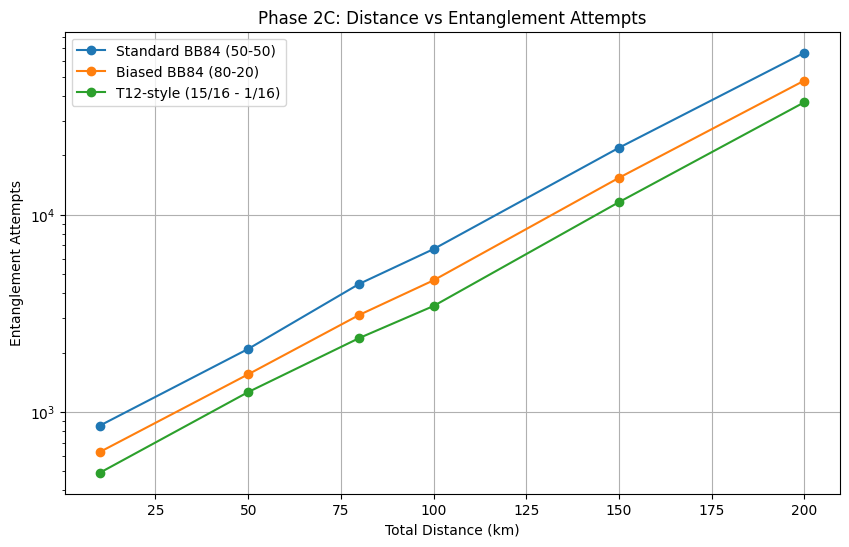

In [ ]:
# @title Distance vs Entanglement Attempts

plt.figure(figsize=(10, 6))

for protocol_name in protocols.keys():
    subset = df_phase2c_distance_sweep[
        df_phase2c_distance_sweep["Protocol"] == protocol_name
    ]

    plt.plot(
        subset["Distance (km)"],
        subset["Entanglement Attempts"],
        marker="o",
        label=protocol_name
    )

plt.xlabel("Total Distance (km)")
plt.ylabel("Entanglement Attempts")
plt.title("Phase 2C: Distance vs Entanglement Attempts")
plt.yscale("log")
plt.legend()
plt.grid(True)

plt.savefig(
    "Phase 2C Distance vs Entanglement Attempts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

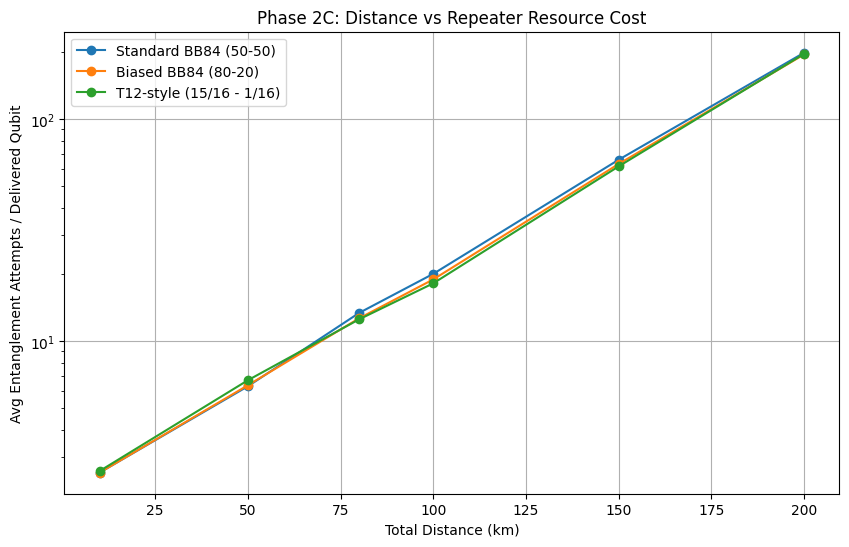

In [ ]:
# @title Distance vs Avg Entanglement Attempts per Delivered Qubit

plt.figure(figsize=(10, 6))

for protocol_name in protocols.keys():
    subset = df_phase2c_distance_sweep[
        df_phase2c_distance_sweep["Protocol"] == protocol_name
    ]

    plt.plot(
        subset["Distance (km)"],
        subset["Avg Entanglement Attempts / Delivered Qubit"],
        marker="o",
        label=protocol_name
    )

plt.xlabel("Total Distance (km)")
plt.ylabel("Avg Entanglement Attempts / Delivered Qubit")
plt.title("Phase 2C: Distance vs Repeater Resource Cost")
plt.yscale("log")
plt.legend()
plt.grid(True)

plt.savefig(
    "Phase 2C Distance vs Avg Entanglement Attempts per Delivered Qubit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# @title Phase 2C : Non-Ideal Repeater Parameter Sweep

test_distance = 100
target_bits = 128
transmission_margin = 1.3

source_fidelities = [1.0, 0.98, 0.95, 0.90]
swap_success_probabilities = [1.0, 0.95, 0.90, 0.80]

# Keep T12 here first because it is most efficient.
# Later we can repeat this for all protocols if needed.
test_protocol_name = "T12-style (15/16 - 1/16)"
test_z_probability = 15/16

nonideal_results = []

for sf in source_fidelities:
    for p_swap in swap_success_probabilities:

        # Patch: use source fidelity in Bell-pair generation by temporarily setting global wrapper.
        # For now, fidelity affects final BellPair fidelity but not success probability.
        # Swap probability affects whether entanglement swapping succeeds.

        channel = RepeaterAssistedQuantumChannel(
            source=alice,
            repeater=r1,
            destination=bob,
            total_distance_km=test_distance,
            swapping_success_probability=p_swap,
            memory_lifetime_attempts=10_000,
            max_entanglement_attempts=1_000_000
        )

        key, meta = generate_bb84_session_key_over_repeater_channel(
            channel=channel,
            target_bits=target_bits,
            transmission_margin=transmission_margin,
            max_rounds=100,
            eve_present=False,
            z_probability=test_z_probability,
            verbose=False
        )

        # Approximate final fidelity:
        # One end-to-end Bell pair combines two elementary Bell pairs.
        # For sf on each elementary pair: final ≈ sf^2
        # If swap is imperfect, include swap success quality separately later.
        approx_final_fidelity = sf ** 2

        nonideal_results.append({
            "Protocol": test_protocol_name,
            "Distance (km)": test_distance,
            "Source Fidelity": sf,
            "Swap Success Probability": p_swap,
            "Approx Final Fidelity": approx_final_fidelity,
            "Qubits Sent": meta["total_qubits_sent"],
            "Qubits Received": meta["total_qubits_received"],
            "Entanglement Attempts": meta["total_entanglement_attempts"],
            "Avg Entanglement Attempts / Delivered Qubit":
                meta["average_entanglement_attempts_per_delivered_qubit"],
            "Swap Attempts": meta["swap_attempts"],
            "Successful End-to-End Bell Pairs": meta["successful_end_to_end_bell_pairs"],
            "Effective Key Yield (%)": meta["effective_key_yield"] * 100,
            "Keygen Time (s)": meta["keygen_time_s"]
        })

df_phase2c_nonideal = pd.DataFrame(nonideal_results)

df_phase2c_nonideal.to_csv(
    "phase2c_nonideal_repeater_parameter_sweep.csv",
    index=False
)

display(df_phase2c_nonideal)

,Protocol,Distance (km),Source Fidelity,Swap Success Probability,Approx Final Fidelity,Qubits Sent,Qubits Received,Entanglement Attempts,Avg Entanglement Attempts / Delivered Qubit,Swap Attempts,Successful End-to-End Bell Pairs,Effective Key Yield (%),Keygen Time (s)
0,T12-style (15/16 - 1/16),100,1.00,1.00,1.0000,189,189,3902,20.645503,189,189,67.724868,21.452693
1,T12-style (15/16 - 1/16),100,1.00,0.95,1.0000,189,189,4051,21.433862,204,189,67.724868,20.896532
2,T12-style (15/16 - 1/16),100,1.00,0.90,1.0000,189,189,4415,23.359788,221,189,67.724868,20.560753
3,T12-style (15/16 - 1/16),100,1.00,0.80,1.0000,189,189,4805,25.423280,235,189,67.724868,21.150875
4,T12-style (15/16 - 1/16),100,0.98,1.00,0.9604,189,189,3771,19.952381,189,189,67.724868,20.756787
5,T12-style (15/16 - 1/16),100,0.98,0.95,0.9604,189,189,3964,20.973545,196,189,67.724868,21.024952
6,T12-style (15/16 - 1/16),100,0.98,0.90,0.9604,189,189,4038,21.365079,212,189,67.724868,21.231264
7,T12-style (15/16 - 1/16),100,0.98,0.80,0.9604,189,189,4846,25.640212,243,189,67.724868,21.028196
8,T12-style (15/16 - 1/16),100,0.95,1.00,0.9025,189,189,3783,20.015873,189,189,67.724868,19.969892
9,T12-style (15/16 - 1/16),100,0.95,0.95,0.9025,189,189,3663,19.380952,193,189,67.724868,20.905161
